# Phase 1: Cardiotocography (CTG) Exploratory Data Analysis (EDA)

**Project:** Agent-Based Model for Fetal Well-being Assessment  
**Goal:** Understand the dual-modality data (1 kHz Doppler Ultrasound audio vs. 4 Hz Fetal Heart Rate) and run the Task 1 AutoFHR baseline.

---
### Clinical Overview (FIGO 2015 Guidelines)
- **Baseline FHR:** Normal resting rate is **110 – 160 bpm**.
- **Variability:** Normal beat-to-beat fluctuations are **5 – 25 bpm**.
- **Accelerations:** Transient jumps $\ge 15$ bpm for $\ge 15$ seconds (reassuring sign of fetal movement).
- **Decelerations:** Transient drops $\ge 15$ bpm for $\ge 15$ seconds (potential sign of cord compression or hypoxia).

## Step 1: Environment & Path Setup
Let's import our core numerical and signal processing libraries, and link to the `ctg_baseline` modules.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.io import wavfile
import matplotlib.pyplot as plt
import torch

# Set up project roots (works whether running from workspace or D: drive)
REPO_ROOT = Path(r"c:\Users\prajin\Documents\CTG Challenge\ctg-agent-fetal-assessment-baseline")
if not REPO_ROOT.exists():
    REPO_ROOT = Path(r"D:\CTG_Challenge\ctg-agent-fetal-assessment-baseline")

sys.path.insert(0, str(REPO_ROOT))

from ctg_baseline.io import load_fetal_fhr, load_fhr
from ctg_baseline.signal_processing import DUS_filtering, create_scalogram_from_signal
from ctg_baseline.tools import Task1Tool

print(f"Project root linked: {REPO_ROOT}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")

Project root linked: c:\Users\prajin\Documents\CTG Challenge\ctg-agent-fetal-assessment-baseline
CUDA available: True
GPU Device: NVIDIA GeForce RTX 4050 Laptop GPU


## Step 2: Inspecting the Challenge Manifests
Let's inspect the Task 1 training manifest (`train.csv`), which pairs each audio file with its ground-truth reference.

In [2]:
manifest_path = REPO_ROOT / "data/task1/manifests/train.csv"
df_manifest = pd.read_csv(manifest_path)

print(f"Total training records in Task 1: {len(df_manifest)}")
df_manifest.head()

Total training records in Task 1: 3016


,record_id,wav_path,fetal_path
0,t1_00001,task1/data/train/wav/t1_00001.wav,task1/labels/train/fetal/t1_00001.fetal
1,t1_00002,task1/data/train/wav/t1_00002.wav,task1/labels/train/fetal/t1_00002.fetal
2,t1_00003,task1/data/train/wav/t1_00003.wav,task1/labels/train/fetal/t1_00003.fetal
3,t1_00004,task1/data/train/wav/t1_00004.wav,task1/labels/train/fetal/t1_00004.fetal
4,t1_00005,task1/data/train/wav/t1_00005.wav,task1/labels/train/fetal/t1_00005.fetal


## Step 3: Loading & Inspecting Raw Audio (1 kHz DUS)
Let's inspect our first patient recording (`t1_00001.wav`). Each recording covers exactly 20 minutes (1,200 seconds) at 1,000 Hz = 1,200,000 audio samples.

In [3]:
sample_row = df_manifest.iloc[0]
wav_path = REPO_ROOT / "data" / sample_row["wav_path"]
fetal_path = REPO_ROOT / "data" / sample_row["fetal_path"]

fs_wav, raw_audio = wavfile.read(wav_path)
if raw_audio.ndim > 1:
    raw_audio = raw_audio[:, 0]
raw_audio = raw_audio.astype(np.float32)
duration_sec = len(raw_audio) / fs_wav

print(f"Record ID: {sample_row['record_id']}")
print(f"Sampling Rate: {fs_wav} Hz")
print(f"Total Samples: {len(raw_audio):,}")
print(f"Duration: {duration_sec:.1f} seconds ({duration_sec / 60:.1f} minutes)")
print(f"Amplitude Range: [{raw_audio.min():.1f}, {raw_audio.max():.1f}]")

Record ID: t1_00001
Sampling Rate: 1000 Hz
Total Samples: 1,200,000
Duration: 1200.0 seconds (20.0 minutes)
Amplitude Range: [0.0, 255.0]


## Step 4: Decoding the Binary Ground Truth (`.fetal`)
The reference heart rate is stored in a custom binary layout with an 8-byte header followed by 4,800 samples on a 4 Hz time axis ($1200\text{ s} \times 4\text{ Hz} = 4800\text{ points}$). Values outside $[50, 210]\text{ bpm}$ are marked as `NaN` (dropouts).

In [4]:
reference_fhr = load_fetal_fhr(fetal_path)
time_axis = np.arange(len(reference_fhr)) / 4.0
valid_points = np.isfinite(reference_fhr)
valid_values = reference_fhr[valid_points]

print(f"Total FHR Points: {len(reference_fhr)}")
print(f"Valid Points: {np.sum(valid_points)} / {len(reference_fhr)} ({np.mean(valid_points)*100:.2f}% coverage)")
print(f"Baseline Mean: {valid_values.mean():.2f} bpm")
print(f"Baseline Median: {np.median(valid_values):.2f} bpm")
print(f"Variability (Std Dev): {valid_values.std():.2f} bpm")
print(f"Range: [{valid_values.min():.1f}, {valid_values.max():.1f}] bpm")

Total FHR Points: 4800
Valid Points: 4800 / 4800 (100.00% coverage)
Baseline Mean: 125.78 bpm
Baseline Median: 126.00 bpm
Variability (Std Dev): 4.48 bpm
Range: [107.0, 147.0] bpm


## Step 5: Visualizing DUS Audio & Continuous Wavelet Transform (CWT)
Let's look at 5 seconds of raw audio (sec 10 to 15) and compute a Morlet CWT scalogram ($1000 \times 40$) over a 3.75-second window to see how the muffled audio turns into clear periodic heartbeat energy peaks!

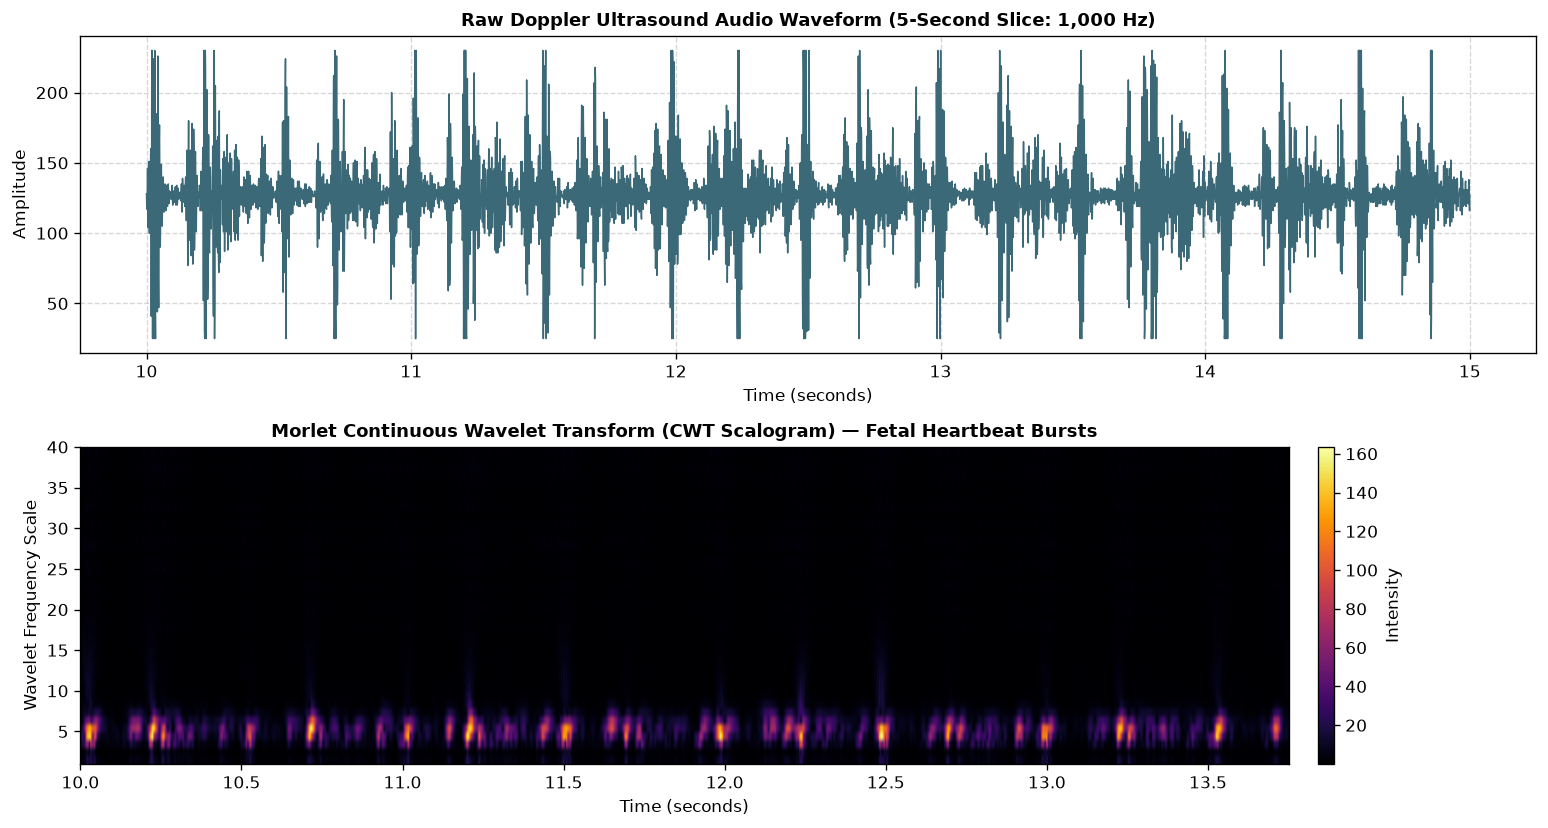

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), dpi=120)

# Plot 5 seconds of raw audio
t_slice = np.linspace(10, 15, int(5 * fs_wav))
audio_5s = raw_audio[fs_wav * 10 : fs_wav * 15]
ax1.plot(t_slice, audio_5s, color='#3B6978', lw=0.9)
ax1.set_title("Raw Doppler Ultrasound Audio Waveform (5-Second Slice: 1,000 Hz)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Amplitude")
ax1.grid(True, linestyle='--', alpha=0.5)

# Filter & compute 3.75-second Morlet CWT scalogram
slice_375 = raw_audio[fs_wav * 10 : fs_wav * 10 + int(3.75 * fs_wav)]
filtered = DUS_filtering(slice_375, fs=fs_wav, lowcut=50.0, highcut=600.0)
scalogram = create_scalogram_from_signal(filtered, fs=fs_wav, time_bins=1000, freq_bins=40)

im = ax2.imshow(scalogram, aspect='auto', origin='lower', extent=[10, 13.75, 1, 40], cmap='inferno')
ax2.set_title("Morlet Continuous Wavelet Transform (CWT Scalogram) — Fetal Heartbeat Bursts", fontsize=11, fontweight='bold')
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Wavelet Frequency Scale")
fig.colorbar(im, ax=ax2, orientation='vertical', pad=0.02, label='Intensity')

plt.tight_layout()
plt.show()

## Step 6: Full 20-Minute Clinical Trace with FIGO Guideline Band
Let's plot the complete 20-minute FHR curve and overlay the official FIGO normal corridor (110–160 bpm).

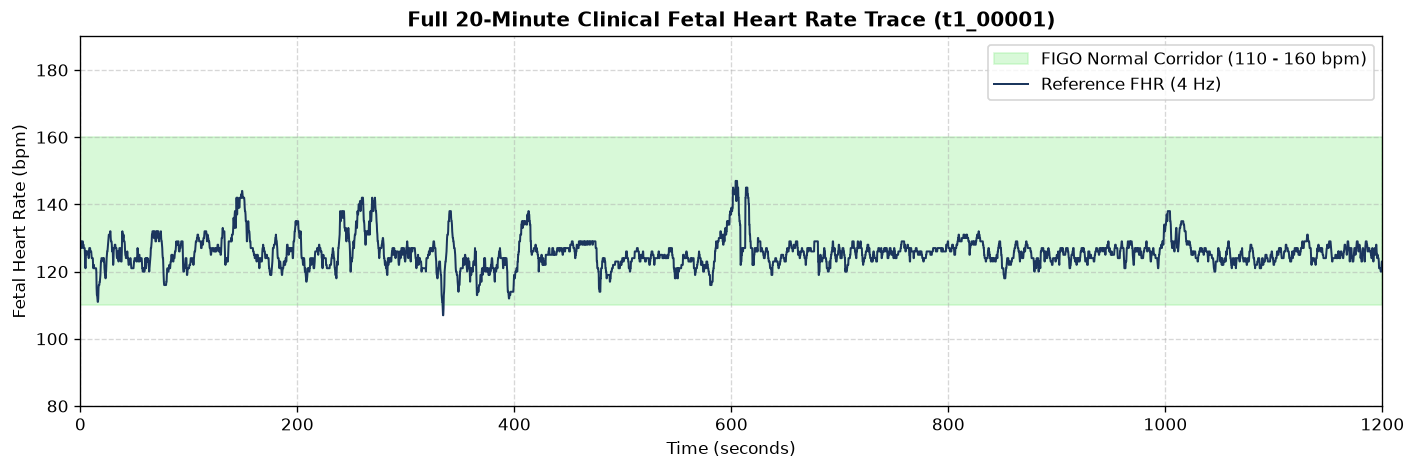

In [6]:
plt.figure(figsize=(14, 4), dpi=120)
plt.axhspan(110, 160, color='lightgreen', alpha=0.35, label='FIGO Normal Corridor (110 - 160 bpm)')
plt.plot(time_axis, reference_fhr, color='#1B365D', lw=1.2, label='Reference FHR (4 Hz)')
plt.xlim(0, 1200)
plt.ylim(80, 190)
plt.title(f"Full 20-Minute Clinical Fetal Heart Rate Trace ({sample_row['record_id']})", fontsize=12, fontweight='bold')
plt.xlabel("Time (seconds)")
plt.ylabel("Fetal Heart Rate (bpm)")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Step 7: Running Task 1 AutoFHR Reconstruction & Accuracy Metrics
Now let's pass `t1_00001.wav` through the pretrained **AutoFHR** model on the GPU, reconstruct the heart rate curve, and compare it against the reference ground truth using:
- **MAE (Mean Absolute Error):** Average difference in bpm.
- **$R^2$ Score (Coefficient of Determination):** How closely the reconstruction tracks true variability.

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running AutoFHR inference on: {device}")

# Initialize Task 1 Tool
task1_tool = Task1Tool(device)

# Run reconstruction
result = task1_tool.run(wav_path, batch_size=32)
predicted_fhr = result["fhr"]
missing_rate = result["missing_rate"]
coverage = result["coverage"]

print(f"Reconstruction Complete!")
print(f"Coverage: {coverage * 100:.2f}%, Missing Rate: {missing_rate * 100:.2f}%")

# Compute Error Metrics on valid reference points
mask = np.isfinite(reference_fhr) & np.isfinite(predicted_fhr)
mae = np.mean(np.abs(predicted_fhr[mask] - reference_fhr[mask]))
ss_res = np.sum((reference_fhr[mask] - predicted_fhr[mask]) ** 2)
ss_tot = np.sum((reference_fhr[mask] - np.mean(reference_fhr[mask])) ** 2)
r2 = 1.0 - (ss_res / ss_tot)

print(f"Mean Absolute Error (MAE): {mae:.2f} bpm")
print(f"R^2 Accuracy Score: {r2:.4f}")

Running AutoFHR inference on: cuda


Reconstruction Complete!
Coverage: 100.00%, Missing Rate: 0.00%
Mean Absolute Error (MAE): 2.99 bpm
R^2 Accuracy Score: 0.2987


## Step 8: Overlaying Predicted FHR vs. Ground Truth
Let's plot both curves directly on top of each other to visually verify the reconstruction fidelity.

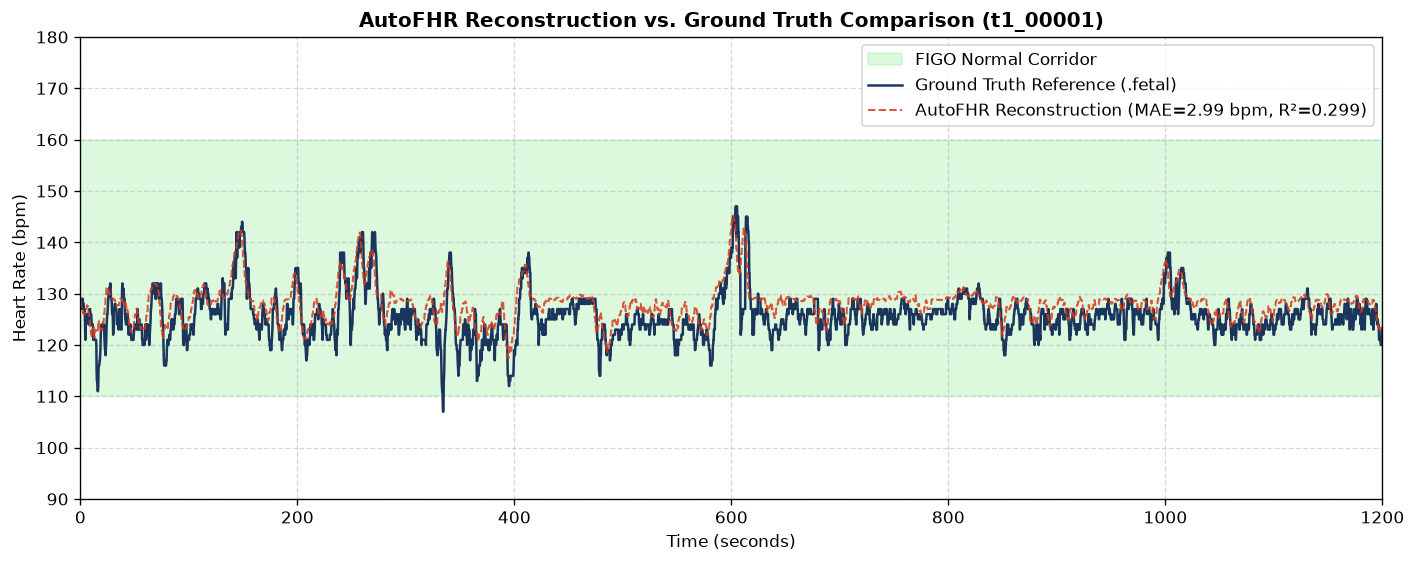

In [8]:
plt.figure(figsize=(14, 5), dpi=120)
plt.axhspan(110, 160, color='lightgreen', alpha=0.3, label='FIGO Normal Corridor')
plt.plot(time_axis, reference_fhr, color='#1B365D', lw=1.5, label='Ground Truth Reference (.fetal)')
plt.plot(time_axis, predicted_fhr, color='#D9381E', lw=1.2, linestyle='--', alpha=0.85, label=f'AutoFHR Reconstruction (MAE={mae:.2f} bpm, R²={r2:.3f})')
plt.xlim(0, 1200)
plt.ylim(90, 180)
plt.title(f"AutoFHR Reconstruction vs. Ground Truth Comparison ({sample_row['record_id']})", fontsize=12, fontweight='bold')
plt.xlabel("Time (seconds)")
plt.ylabel("Heart Rate (bpm)")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()